# Symptom-Based Illness Classification with Logistic Regression

Predict whether a patient has **COVID, Flu, Cold or Allergy** from 20 yes/no symptoms.

Eight models were compared first (KNN, Logistic Regression, SVC, Decision Tree, Random Forest, GBM, XGBoost, MLP). Six of them made exactly the same predictions, so this notebook keeps the simplest one, **Logistic Regression**, and looks at it in more detail.

The data is synthetic, so this is a modelling exercise and not a clinical tool.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)

# works both in the repo (notebooks/ folder) and in Colab (csv uploaded next to the notebook)
if os.path.exists('../data/raw/covid_flu_cold.csv'):
    data_path, fig_dir = '../data/raw/covid_flu_cold.csv', '../reports/figures'
else:
    data_path, fig_dir = 'covid_flu_cold.csv', 'figures'
os.makedirs(fig_dir, exist_ok=True)
sns.set_style('whitegrid')

## 1. Load and check the data

In [2]:
df = pd.read_csv(data_path)

print(df.shape)
print('missing values :', df.isna().sum().sum())
print('duplicate rows :', df.duplicated().sum())
df['TYPE'].value_counts()

(44453, 21)
missing values : 0
duplicate rows : 0


,count
TYPE,
FLU,25000
ALLERGY,16381
COVID,2048
COLD,1024


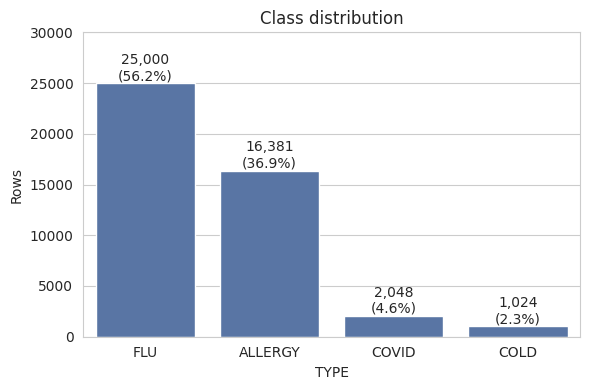

In [3]:
counts = df['TYPE'].value_counts()

plt.figure(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, color='#4c72b0')
for i, v in enumerate(counts.values):
    plt.text(i, v + 300, f'{v:,}\n({v / len(df):.1%})', ha='center')
plt.title('Class distribution')
plt.ylabel('Rows')
plt.ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.savefig(f'{fig_dir}/01_class_distribution.png', dpi=150)
plt.show()

FLU is 56% of the data while COVID and COLD together are only about 7%. A model that always guesses the common classes will still look accurate, so accuracy alone can't be trusted here.

## 2. Prepare features and split

In [4]:
features = df.columns[:20]
class_names = ['ALLERGY', 'COLD', 'COVID', 'FLU']   # alphabetical, same order as the codes 0-3

X = df[features]
y = df['TYPE'].map({name: i for i, name in enumerate(class_names)})

# stratify keeps the small classes in both train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=10, stratify=y
)
print(X_train.shape, X_test.shape)

(35562, 20) (8891, 20)


## 3. Baseline vs balanced class weights

Same model, one setting changed. `class_weight='balanced'` makes a COLD or COVID row count more than a FLU row during training.

In [5]:
def summarize(name, model):
    pred = model.predict(X_test)
    row = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Balanced accuracy': balanced_accuracy_score(y_test, pred),
        'Macro F1': f1_score(y_test, pred, average='macro'),
    }
    recalls = recall_score(y_test, pred, average=None)
    row.update({f'Recall {c}': r for c, r in zip(class_names, recalls)})
    return row

baseline = LogisticRegression(max_iter=1000).fit(X_train, y_train)
balanced = LogisticRegression(max_iter=1000, class_weight='balanced').fit(X_train, y_train)

compare = pd.DataFrame([
    summarize('Default', baseline),
    summarize('class_weight=balanced', balanced)
]).set_index('Model').round(3)
compare

,Accuracy,Balanced accuracy,Macro F1,Recall ALLERGY,Recall COLD,Recall COVID,Recall FLU
Model,,,,,,,
Default,0.933,0.774,0.762,0.983,0.644,0.524,0.945
class_weight=balanced,0.932,0.956,0.812,0.968,1.000,0.951,0.905


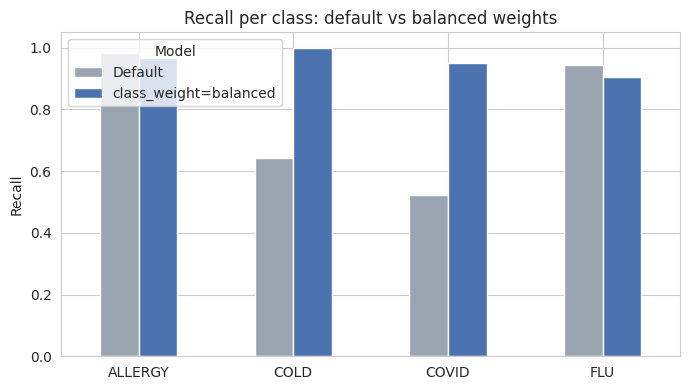

In [6]:
recall_cols = [f'Recall {c}' for c in class_names]
compare[recall_cols].T.rename(index=lambda s: s.replace('Recall ', '')).plot(
    kind='bar', figsize=(7, 4), color=['#9aa5b1', '#4c72b0'])
plt.ylim(0, 1.05)
plt.ylabel('Recall')
plt.title('Recall per class: default vs balanced weights')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f'{fig_dir}/02_recall_default_vs_balanced.png', dpi=150)
plt.show()

Accuracy barely changes, but recall for COLD and COVID jumps. This is the main reason accuracy was not used to pick the model.

## 4. Tune the model

In [7]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'newton-cg']
}

grid = GridSearchCV(
    LogisticRegression(max_iter=1000, class_weight='balanced'),
    param_grid,
    cv=5,
    scoring='recall_macro',   # every class counts the same
    n_jobs=-1
)
grid.fit(X_train, y_train)

best_lr = grid.best_estimator_
print('Best params :', grid.best_params_)
print('CV macro recall :', round(grid.best_score_, 4))

Best params : {'C': 0.1, 'solver': 'lbfgs'}
CV macro recall : 0.9616


## 5. Evaluate on the test set

In [8]:
pred = best_lr.predict(X_test)

print('Accuracy          :', round(accuracy_score(y_test, pred), 4))
print('Balanced accuracy :', round(balanced_accuracy_score(y_test, pred), 4))
print('Macro F1          :', round(f1_score(y_test, pred, average='macro'), 4))
print()
print(classification_report(y_test, pred, target_names=class_names, digits=3))

Accuracy          : 0.9323
Balanced accuracy : 0.9559
Macro F1          : 0.8123

              precision    recall  f1-score   support

     ALLERGY      1.000     0.968     0.984      3276
        COLD      0.494     1.000     0.661       205
       COVID      0.499     0.951     0.654       410
         FLU      1.000     0.905     0.950      5000

    accuracy                          0.932      8891
   macro avg      0.748     0.956     0.812      8891
weighted avg      0.965     0.932     0.942      8891



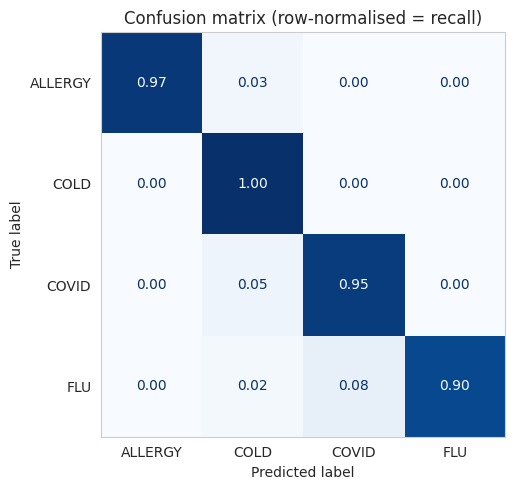

,ALLERGY,COLD,COVID,FLU,ALLERGY (predicted),COLD (predicted),COVID (predicted),FLU (predicted)
Actual in test set,3276,205,410,5000,3171,415,782,4523


In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=class_names, normalize='true',
    values_format='.2f', cmap='Blues', ax=ax, colorbar=False
)
ax.grid(False)
ax.set_title('Confusion matrix (row-normalised = recall)')
plt.tight_layout()
plt.savefig(f'{fig_dir}/03_confusion_matrix.png', dpi=150)
plt.show()

pd.DataFrame(
    np.bincount(y_test, minlength=4).reshape(1, -1), columns=class_names, index=['Actual in test set']
).join(pd.DataFrame(np.bincount(pred, minlength=4).reshape(1, -1), columns=[c + ' (predicted)' for c in class_names], index=['Actual in test set']))

Recall is high for every class, but precision for COLD and COVID is around 0.5. The model catches nearly every real case and pays for it with false alarms, mostly FLU rows labelled COVID or COLD. That trade-off is a choice: it suits a screening tool, not one where a false alarm is expensive.

## 6. How stable is the result?

In [10]:
cv = cross_validate(
    best_lr, X, y,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=10),
    scoring=['accuracy', 'balanced_accuracy', 'f1_macro']
)
for metric in ['accuracy', 'balanced_accuracy', 'f1_macro']:
    s = cv[f'test_{metric}']
    print(f'{metric:18s} {s.mean():.4f} +/- {s.std():.4f}')

accuracy           0.9333 +/- 0.0019
balanced_accuracy  0.9605 +/- 0.0018
f1_macro           0.8163 +/- 0.0038


## 7. Is 93% accuracy a limit?

Some symptom patterns appear under more than one label, and no model can separate those. If we predict the most common label for every pattern, we get the best accuracy any model could reach on this data.

In [11]:
by_pattern = df.groupby(list(features))['TYPE'].agg(lambda s: s.value_counts().iloc[0])
ceiling = by_pattern.sum() / len(df)

print('Best possible accuracy on this data :', round(ceiling, 4))
print('Logistic Regression test accuracy   :', round(accuracy_score(y_test, pred), 4))

Best possible accuracy on this data : 0.9333
Logistic Regression test accuracy   : 0.9323


The model is already at the ceiling. More complex models (SVC, Random Forest, GBM, XGBoost) gave the same predictions, so there is nothing left to gain from them.

## 8. What drives the predictions?

Logistic Regression has one coefficient per symptom per class. A positive value pushes the prediction toward that class, a negative value pushes it away.

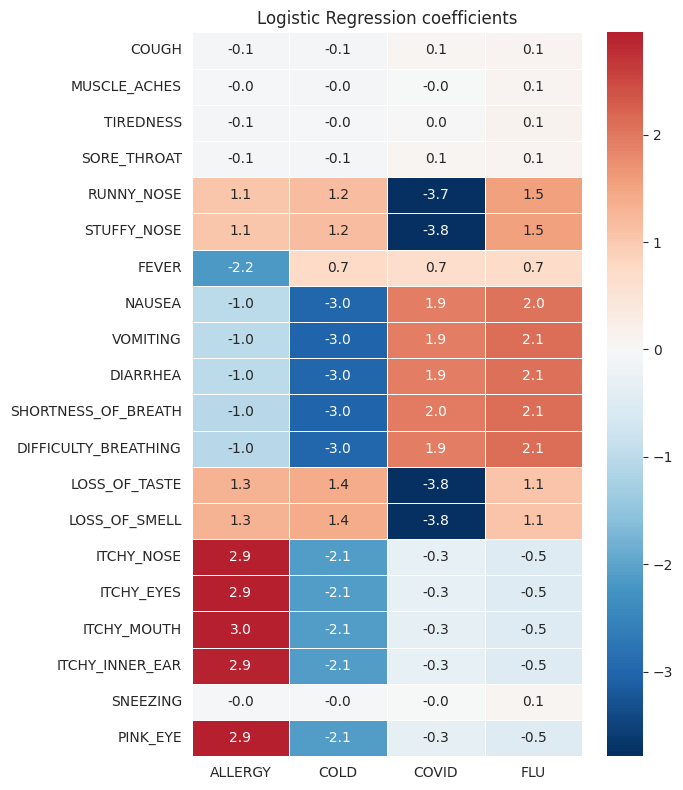

In [12]:
coefs = pd.DataFrame(best_lr.coef_.T, index=features, columns=class_names)

plt.figure(figsize=(7, 8))
sns.heatmap(coefs, cmap='RdBu_r', center=0, annot=True, fmt='.1f', linewidths=0.5)
plt.title('Logistic Regression coefficients')
plt.tight_layout()
plt.savefig(f'{fig_dir}/04_coefficients.png', dpi=150)
plt.show()

In [13]:
for c in class_names:
    top = coefs[c].sort_values(ascending=False)
    print(f'{c:8s} up  :', ', '.join(top.head(4).index))
    print(f'{"":8s} down:', ', '.join(top.tail(4).index))

ALLERGY  up  : ITCHY_MOUTH, ITCHY_EYES, PINK_EYE, ITCHY_NOSE
         down: DIARRHEA, DIFFICULTY_BREATHING, SHORTNESS_OF_BREATH, FEVER
COLD     up  : LOSS_OF_SMELL, LOSS_OF_TASTE, RUNNY_NOSE, STUFFY_NOSE
         down: DIARRHEA, DIFFICULTY_BREATHING, VOMITING, SHORTNESS_OF_BREATH
COVID    up  : SHORTNESS_OF_BREATH, NAUSEA, DIFFICULTY_BREATHING, VOMITING
         down: RUNNY_NOSE, STUFFY_NOSE, LOSS_OF_SMELL, LOSS_OF_TASTE
FLU      up  : SHORTNESS_OF_BREATH, VOMITING, DIFFICULTY_BREATHING, DIARRHEA
         down: PINK_EYE, ITCHY_NOSE, ITCHY_MOUTH, ITCHY_EYES


## 9. Predict for a new patient

In [14]:
def predict_illness(symptoms):
    """symptoms: list of symptom names the patient has, e.g. ['COUGH', 'FEVER']"""
    row = pd.DataFrame([[1 if f in symptoms else 0 for f in features]], columns=features)
    probs = best_lr.predict_proba(row)[0]
    return pd.Series(probs, index=class_names).sort_values(ascending=False).round(3)

predict_illness(['ITCHY_EYES', 'ITCHY_NOSE', 'SNEEZING'])

,0
ALLERGY,0.993
COVID,0.006
COLD,0.000
FLU,0.000


In [15]:
predict_illness(['FEVER', 'COUGH', 'SHORTNESS_OF_BREATH', 'DIARRHEA'])

,0
COVID,0.926
FLU,0.073
COLD,0.000
ALLERGY,0.000


## Conclusion

- Logistic Regression reaches the accuracy ceiling of the dataset (about 0.93) and recovers almost every COLD and COVID case once class weights are balanced.
- Simpler than the other seven models, trains in seconds and its coefficients can be read directly.
- Limits: synthetic data, a single train/test split plus 5-fold CV, and many false alarms for COLD and COVID.